
🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F (Tipo F)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G (Tipo G)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_K (Tipo K)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 448 planetas.

Generating 2D contour map by stellar type for: Area_Estable_km2...


Generando paneles por tipo: 100%|██████████| 4/4 [08:14<00:00, 123.58s/panel]


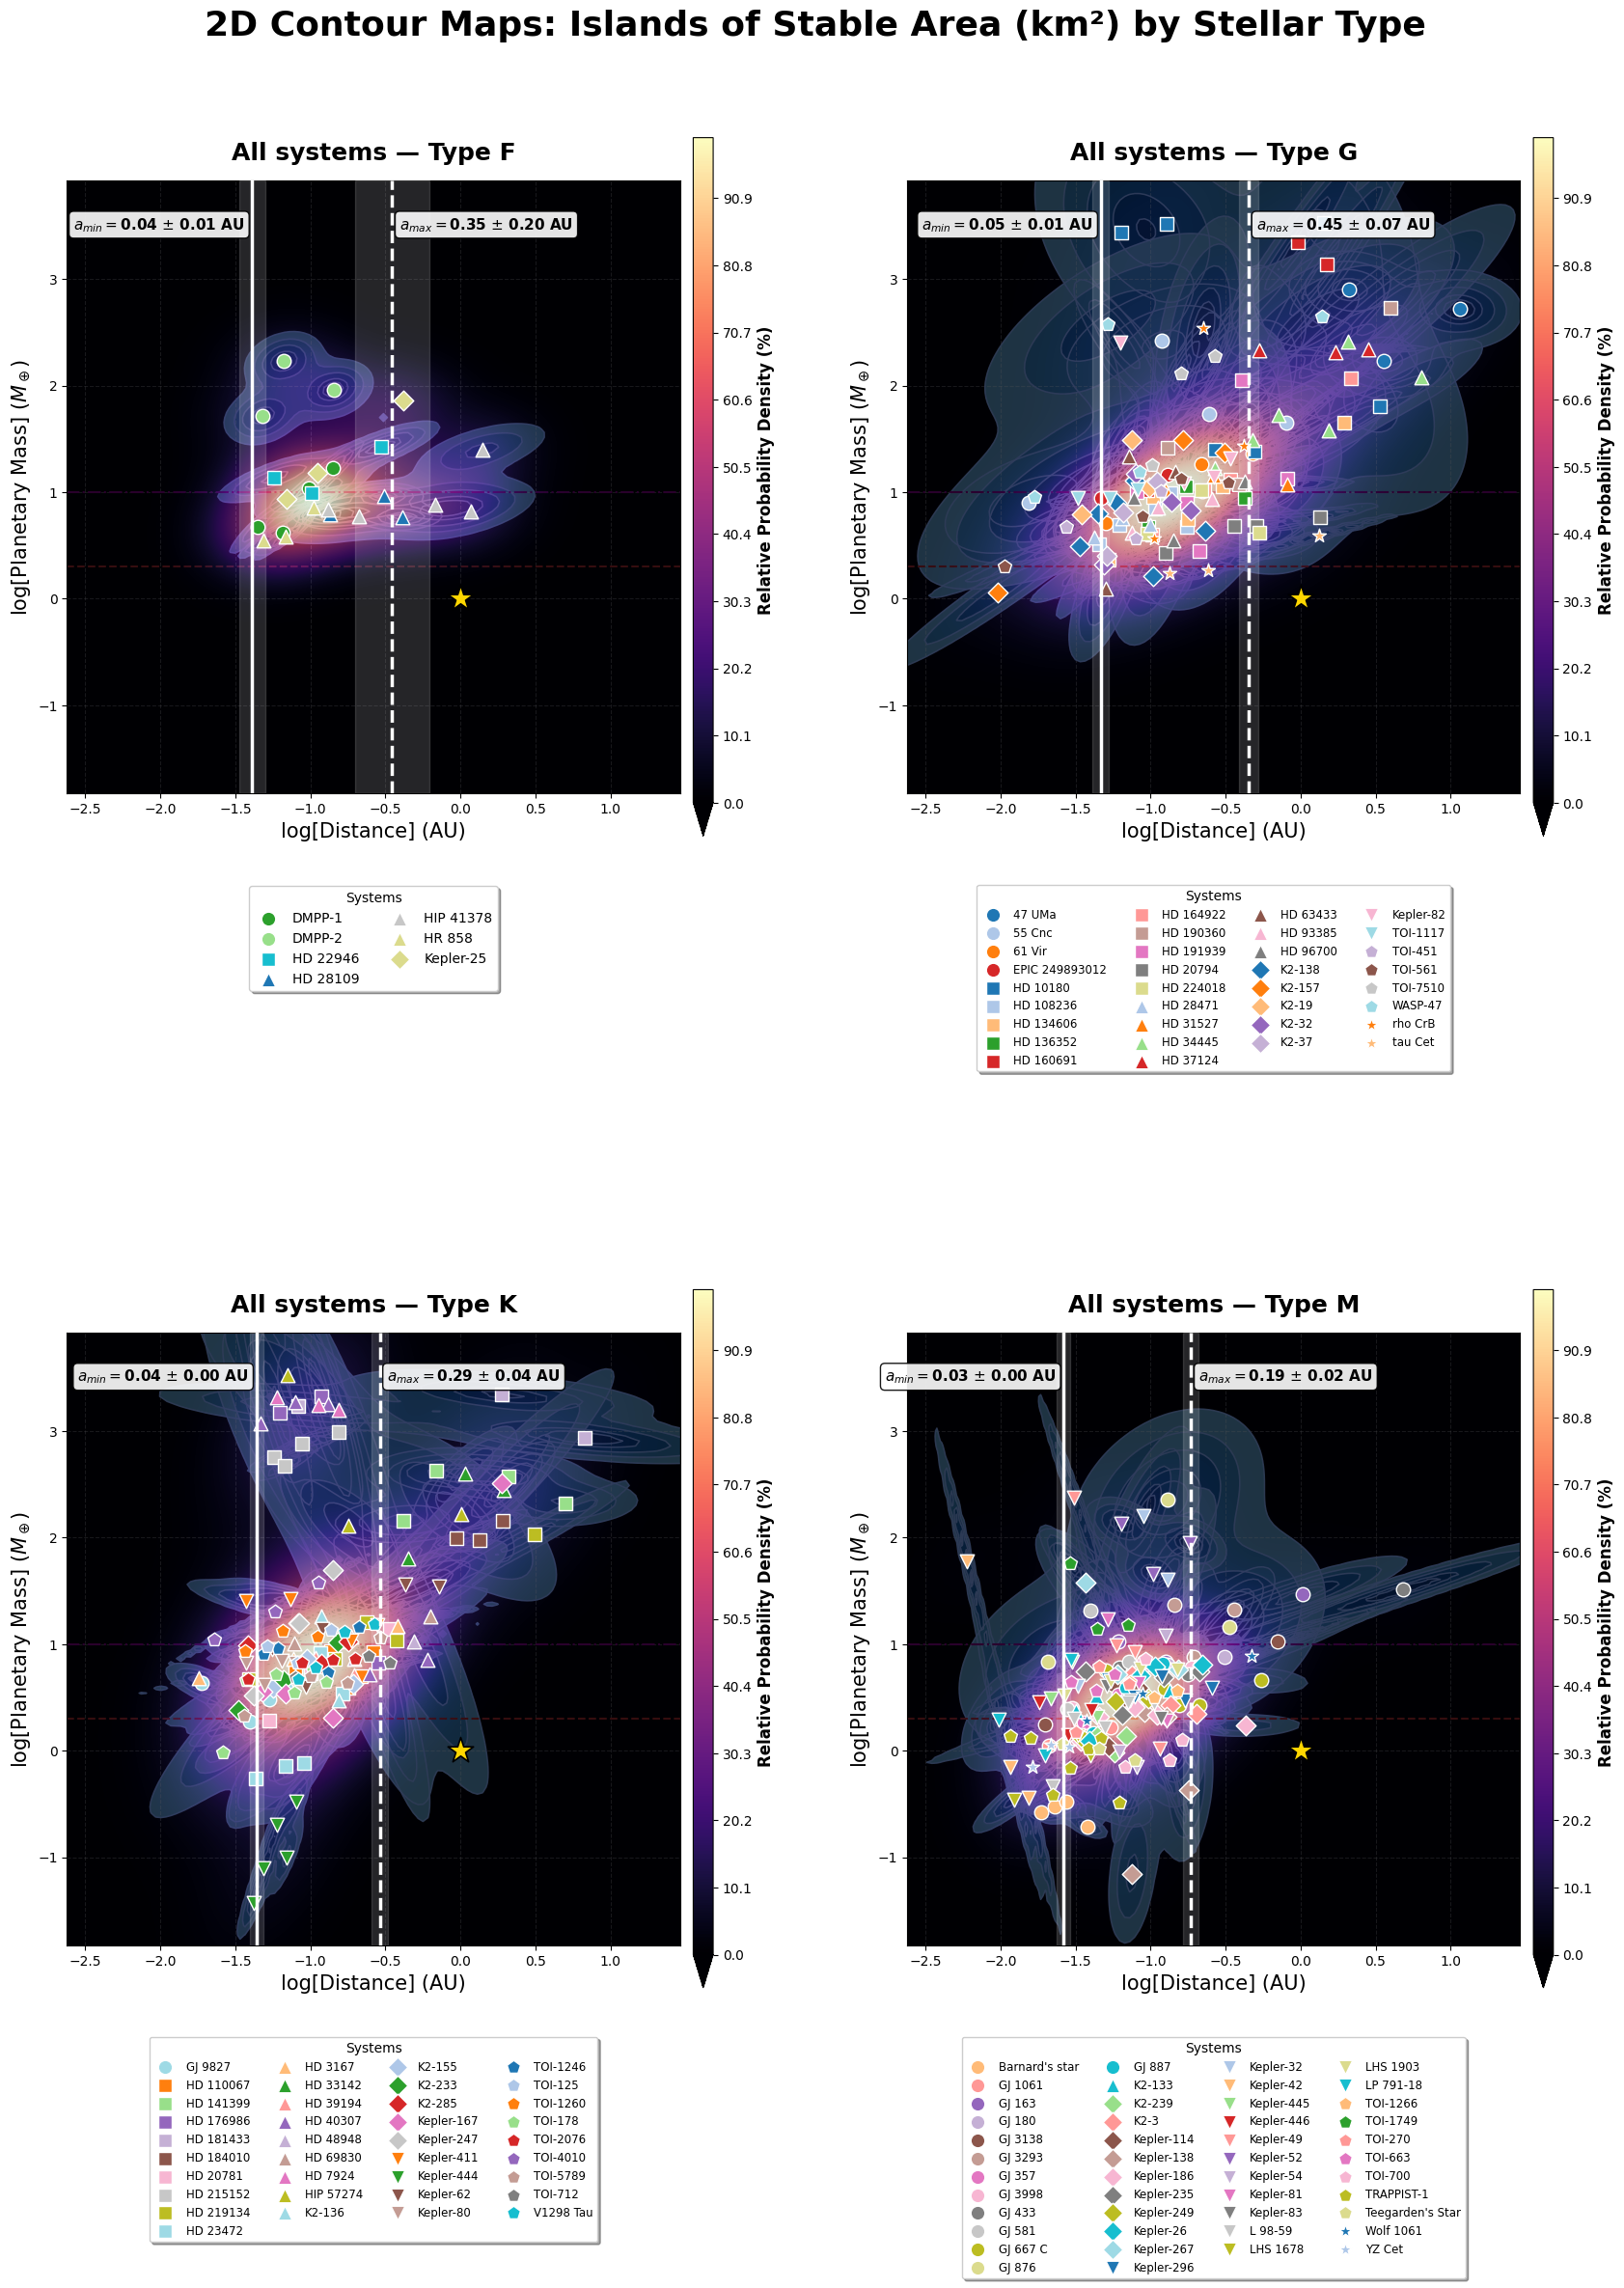


Generando mapas separados (F horizontal, G-K-M en cuadrados 2x2) para: Area_Estable_km2...


Generando paneles Tipo F: 100%|██████████| 3/3 [00:31<00:00, 10.47s/panel]


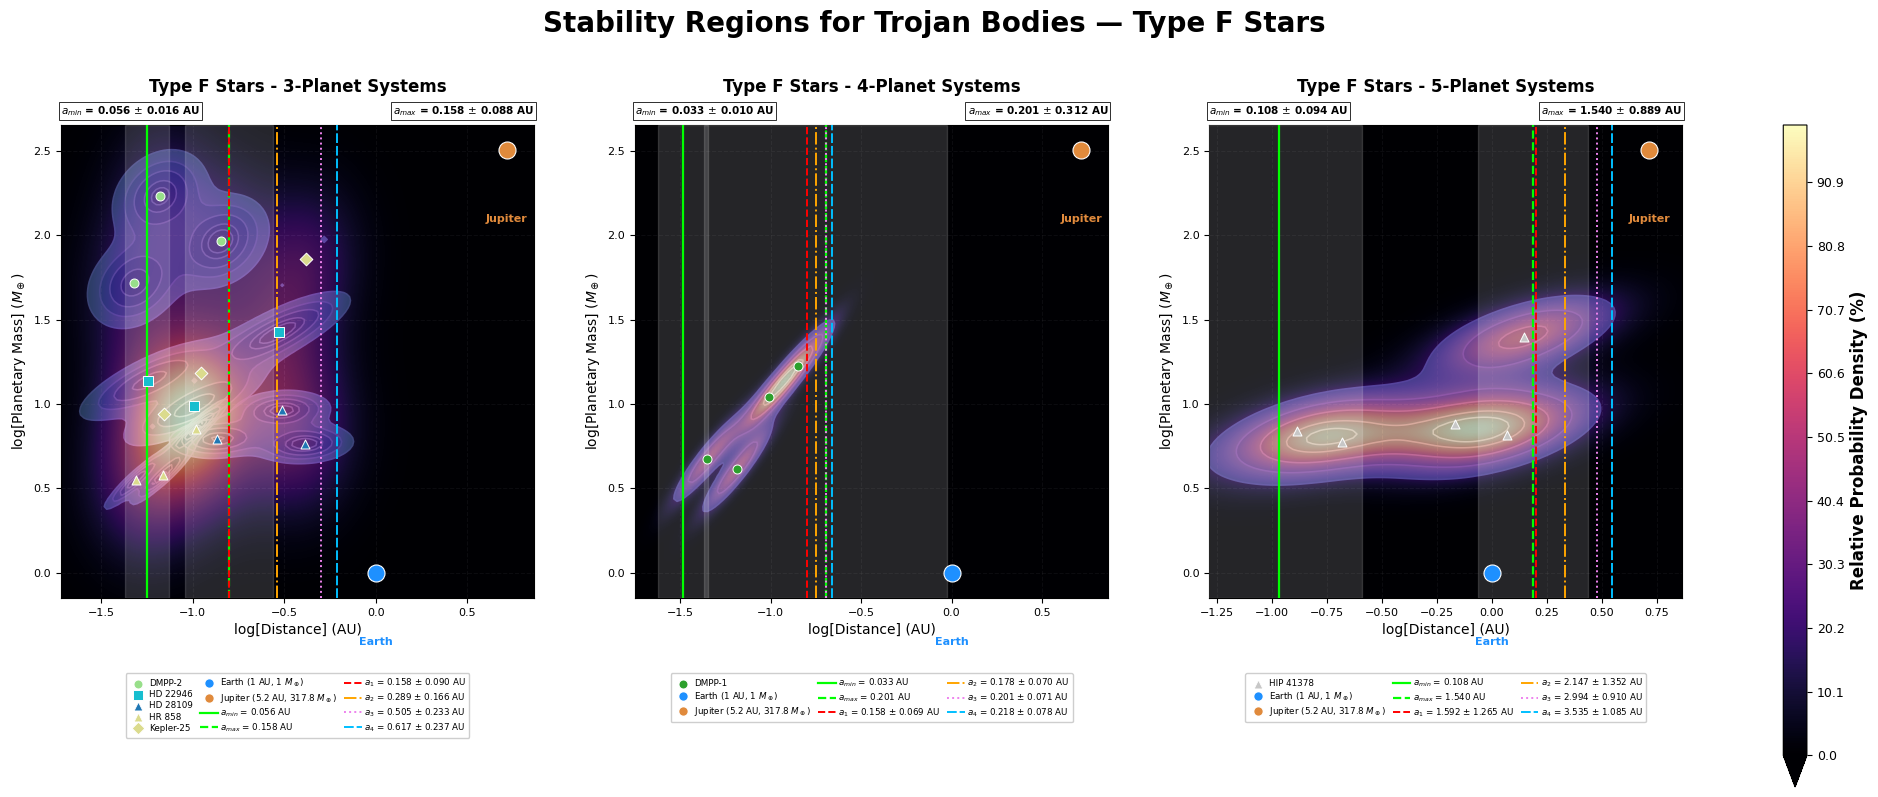

Generando paneles Tipo G: 100%|██████████| 4/4 [01:57<00:00, 29.36s/panel]


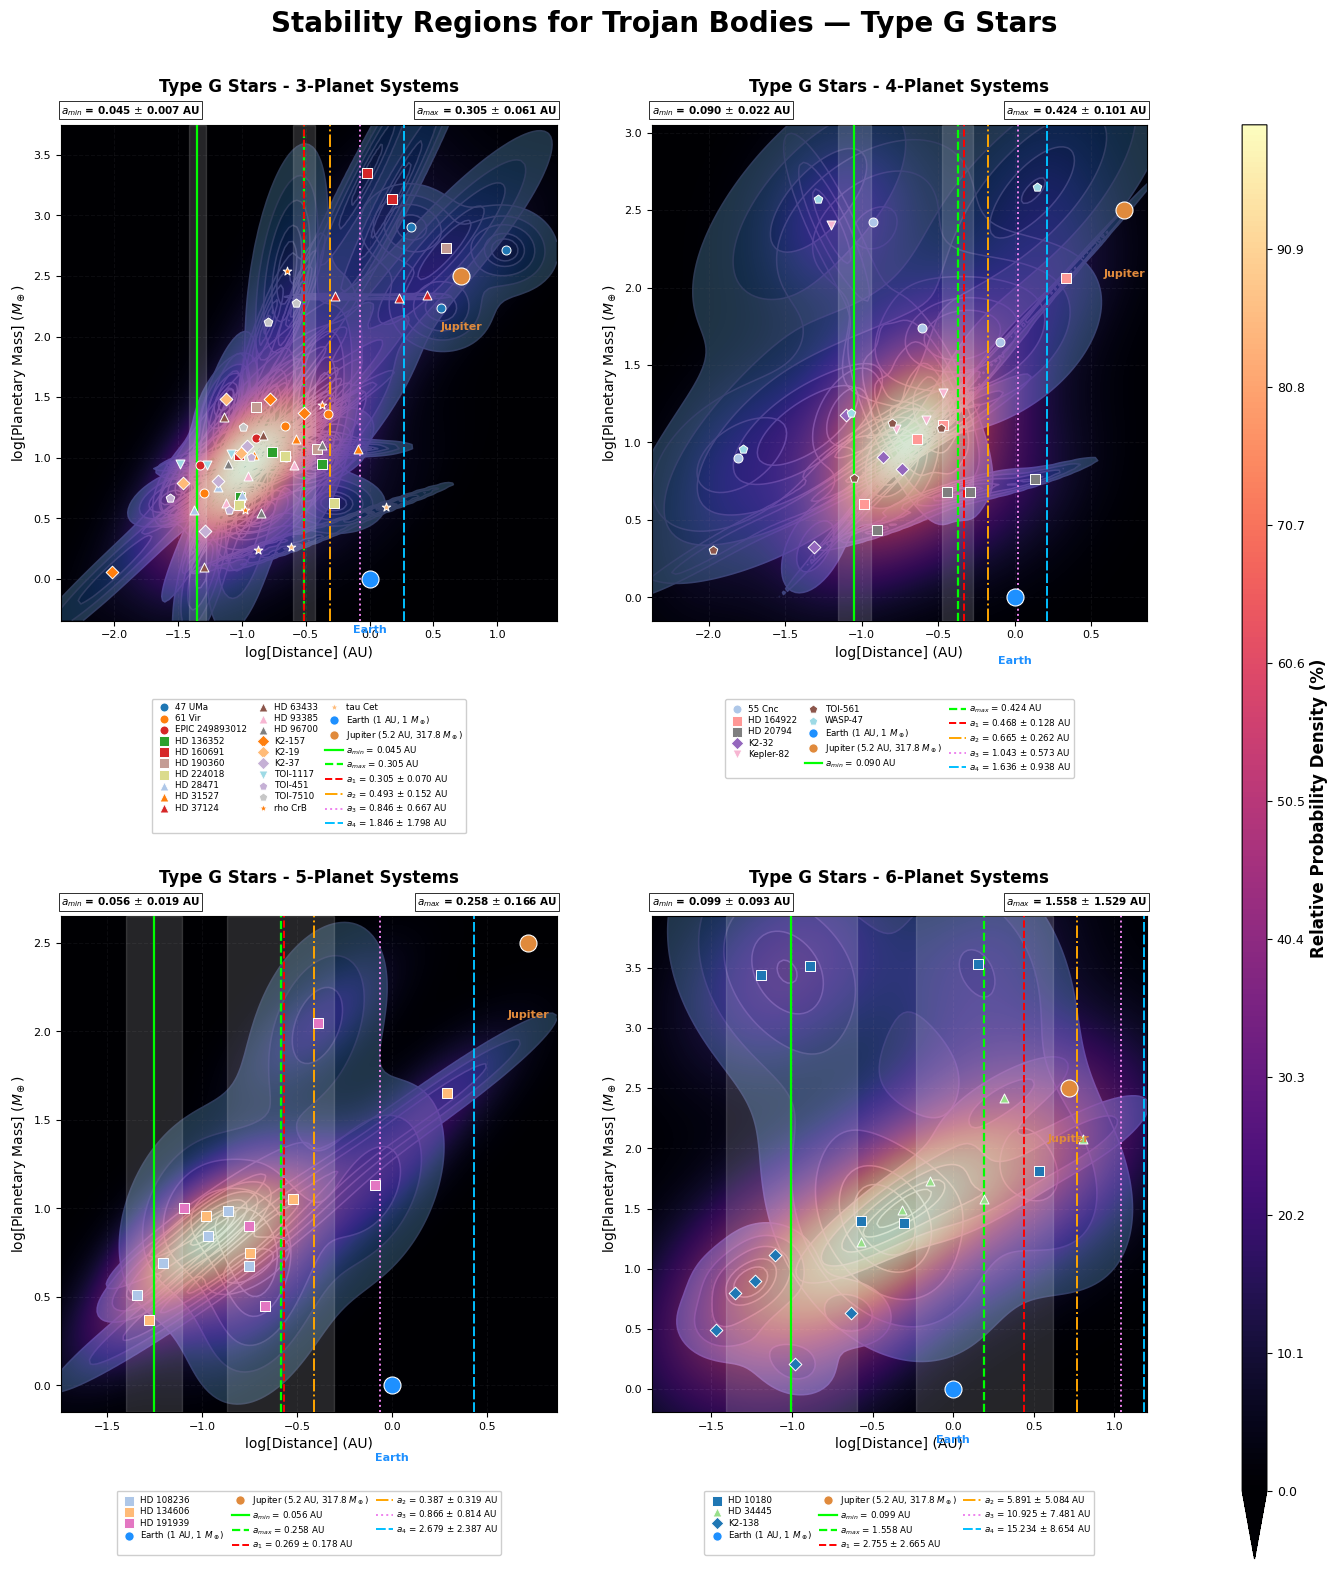

Generando paneles Tipo K: 100%|██████████| 4/4 [02:19<00:00, 34.99s/panel]


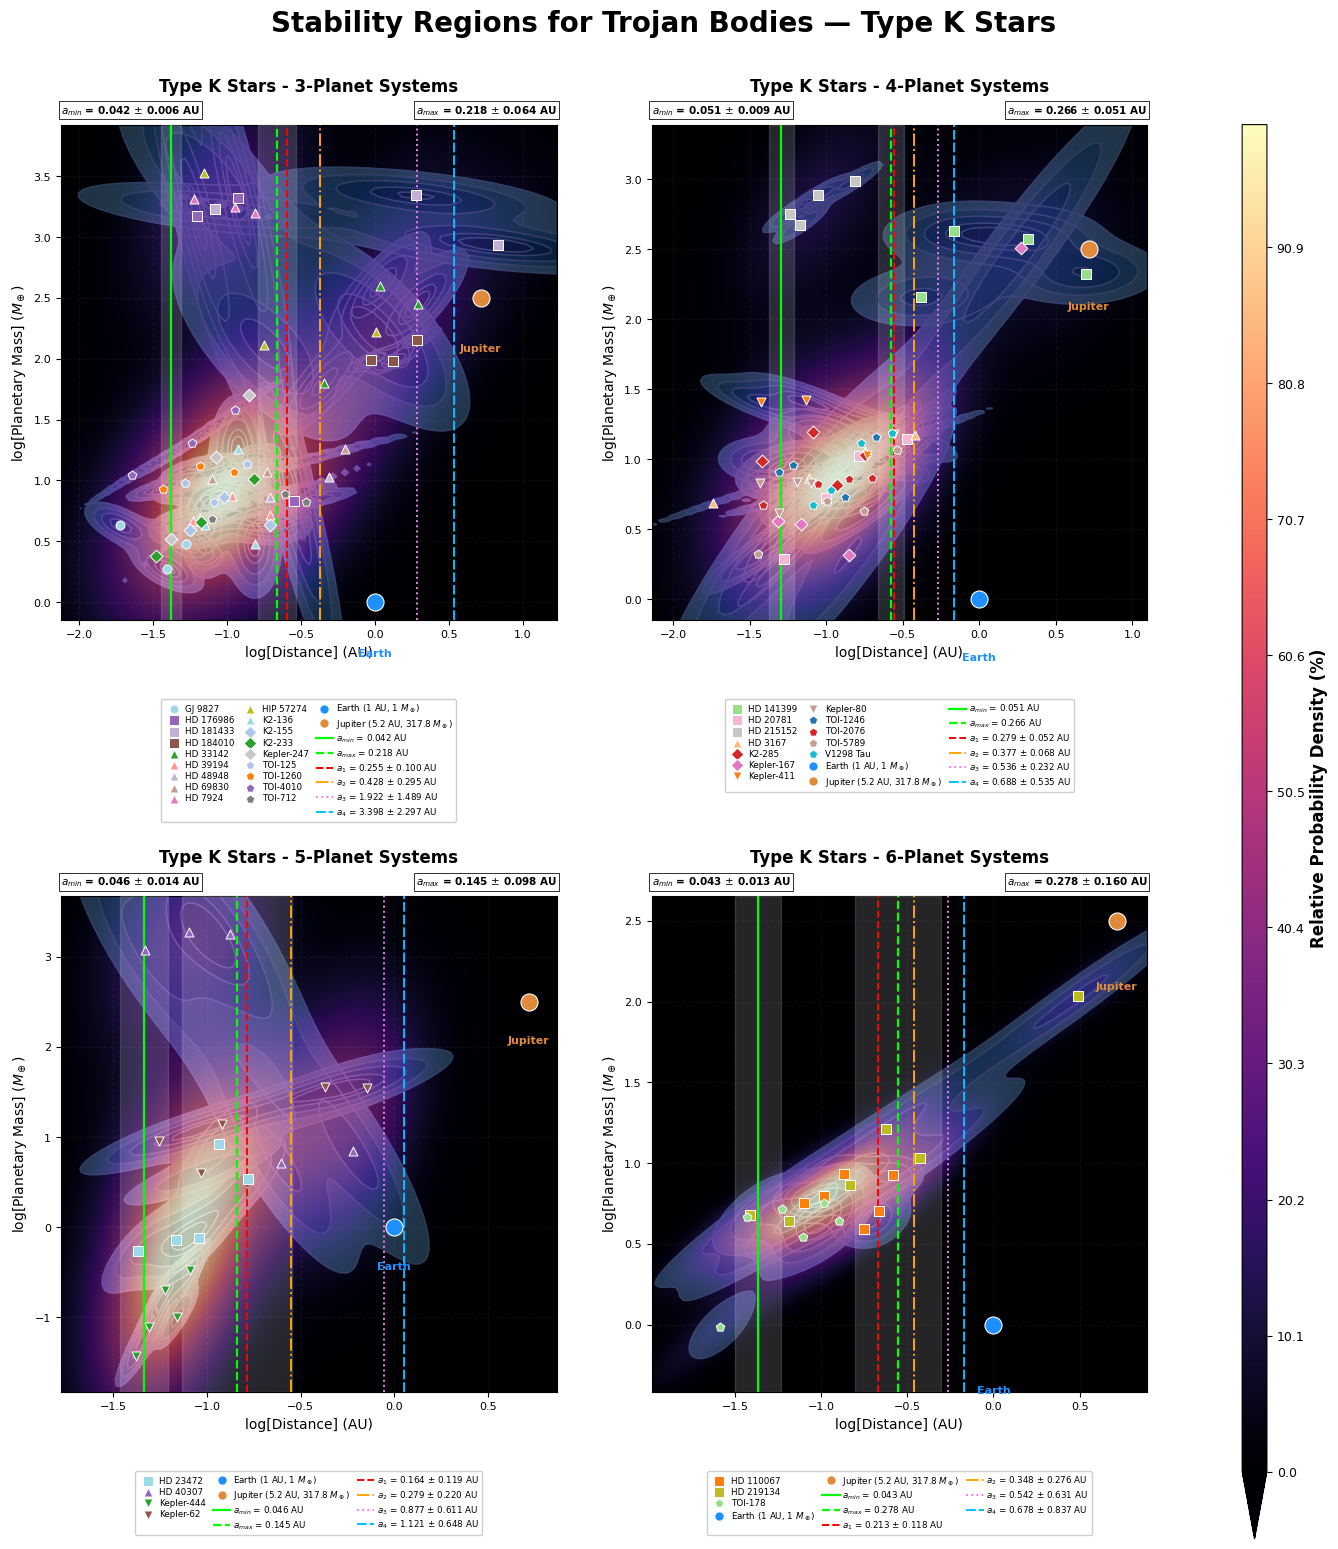

Generando paneles Tipo M: 100%|██████████| 4/4 [02:40<00:00, 40.14s/panel]


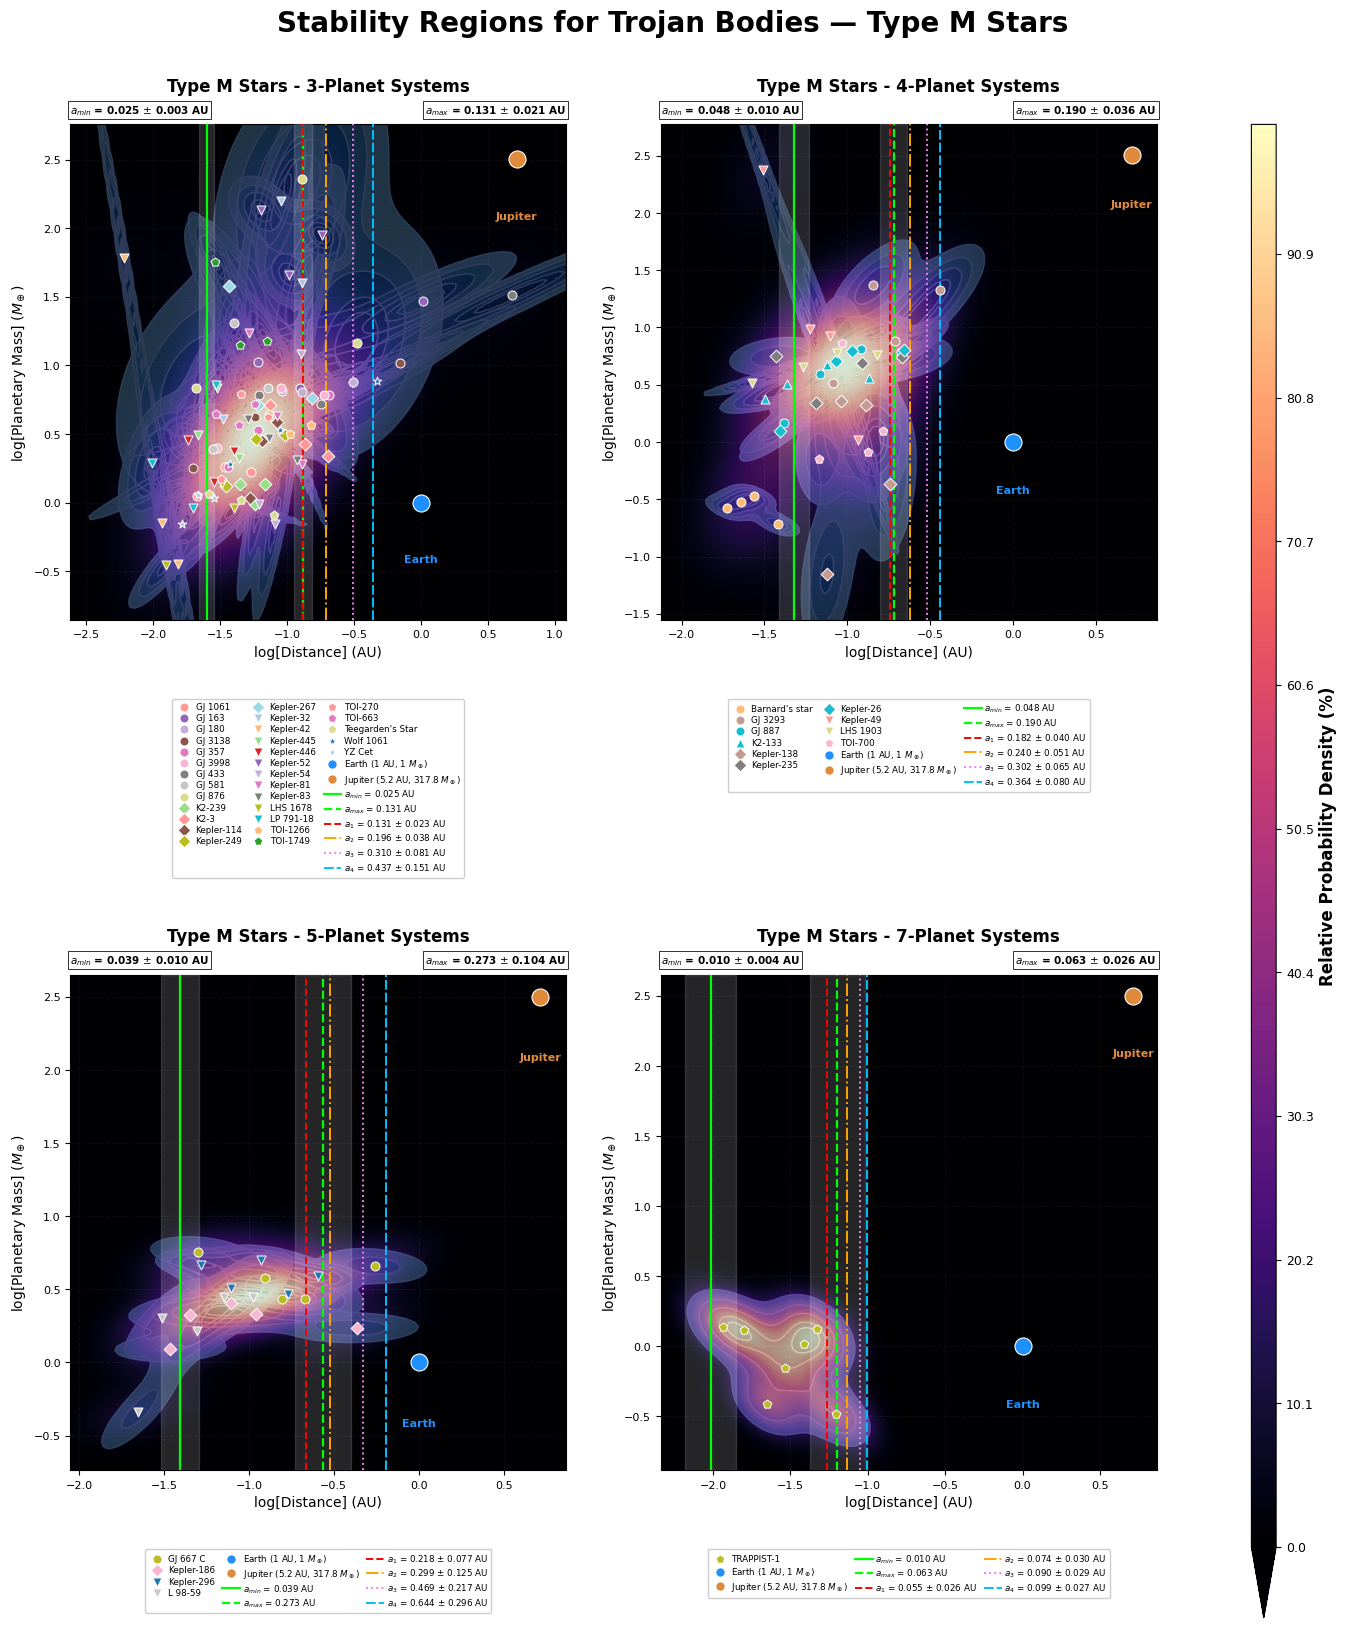

Gráficos guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F\graficos_magma_con_sistemas_azules


In [3]:
import os
import re
import math
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import tkinter as tk
from tkinter import filedialog, simpledialog

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()

# ---------------------------------------------------------------------------
# PARÁMETROS GLOBALES Y UTILIDADES
# ---------------------------------------------------------------------------
N_BOOTSTRAP_INCERTIDUMBRE = 1000   # número de réplicas bootstrap por panel
BOOTSTRAP_GRID_RES = 150j         # malla más gruesa para el bootstrap


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    """
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    marcadores_base = ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"]
    colores_base = plt.cm.tab20.colors
    combinaciones = itertools.product(marcadores_base, colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (por ejemplo, >= 85% / 90.9%).
    """
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, 10), np.percentile(Z_flat, 98), 25)
    umbral = niveles[-4]
    indices_alta_densidad = np.where(Z_pct >= umbral)
    x_alta_densidad = X[indices_alta_densidad]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims,
                                n_bootstrap=N_BOOTSTRAP_INCERTIDUMBRE,
                                grid_res=BOOTSTRAP_GRID_RES, rng=None):
    """
    Estima la incertidumbre asociada al modelo (KDE) en la determinación de
    las distancias críticas a_min y a_max mediante bootstrap no paramétrico.
    """
    if rng is None:
        rng = np.random.default_rng()

    n = len(x)
    log_min_boot, log_max_boot = [], []

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    positions_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap a_min/a_max", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]

        if x_b.var() < 1e-12 or y_b.var() < 1e-12 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.6)
            Z_b = np.reshape(kde_b(positions_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        log_min_b, log_max_b = _calcular_limites_criticos(Z_b, Xb)
        if log_min_b is not None:
            log_min_boot.append(log_min_b)
            log_max_boot.append(log_max_b)

    return log_min_boot, log_max_boot


# ---------------------------------------------------------------------------
# EXTRACCIÓN DE DATOS
# ---------------------------------------------------------------------------
def extraer_datos_personalizados():
    """
    Combina la selección manual de carpetas con el escaneo profundo
    usando expresiones regulares para extraer parámetros físicos y estabilidad.
    """
    root_tk = tk.Tk()
    root_tk.withdraw()
    root_tk.attributes("-topmost", True)

    num_carpetas = simpledialog.askinteger(
        "Cantidad de carpetas",
        "¿Cuántas carpetas principales vas a seleccionar en total?",
        minvalue=1, maxvalue=10, parent=root_tk
    )

    if not num_carpetas:
        root_tk.destroy()
        return pd.DataFrame(), ""

    datos_recopilados = []
    primer_directorio = ""

    for i in range(num_carpetas):
        tipo_estrella = simpledialog.askstring(
            "Tipo de Estrella",
            f"Carpeta {i+1} de {num_carpetas}:\n¿Qué tipo de estrella contiene? (Ej: F, G, K, M)",
            parent=root_tk
        )

        if not tipo_estrella:
            root_tk.destroy()
            return pd.DataFrame(), ""

        tipo_estrella = tipo_estrella.upper().strip()
        directorio_raiz = filedialog.askdirectory(
            title=f"Selecciona la carpeta para los datos de estrellas {tipo_estrella}",
            parent=root_tk
        )

        if not directorio_raiz:
            root_tk.destroy()
            return pd.DataFrame(), ""

        if i == 0:
            primer_directorio = directorio_raiz

        print(f"\n🔍 Escaneando directorio: {directorio_raiz} (Tipo {tipo_estrella})...")

        for root, dirs, files in os.walk(directorio_raiz):
            resumen_file = None
            readme_file = None

            for file in files:
                if file.endswith(" resumen.txt") or file.endswith("_resumen.txt"):
                    resumen_file = file
                elif file.startswith("README") and file.endswith(".txt"):
                    readme_file = file

            if resumen_file and readme_file:
                nombre_planeta = os.path.basename(root).replace("_", " ")
                nombre_sistema = os.path.basename(os.path.dirname(root)).replace("_", " ")

                ruta_resumen = os.path.join(root, resumen_file)
                ruta_readme = os.path.join(root, readme_file)

                try:
                    # 1. LEER RESUMEN
                    with open(ruta_resumen, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_resumen = f.read()

                    z_est_match = re.search(r'Total estables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_inest_match = re.search(r'Total inestables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m1_match = re.search(r'Total colisi[oó]n m1:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m2_match = re.search(r'Total colisi[oó]n m2:\s*(\d+)', contenido_resumen, re.IGNORECASE)

                    z_est = int(z_est_match.group(1)) if z_est_match else 0
                    z_inest = int(z_inest_match.group(1)) if z_inest_match else 0
                    z_m1 = int(z_m1_match.group(1)) if z_m1_match else 0
                    z_m2 = int(z_m2_match.group(1)) if z_m2_match else 0

                    a_est_match = re.search(r'[AÁaá]rea estable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_inest_match = re.search(r'[AÁaá]rea inestable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_col_match = re.search(r'[AÁaá]rea.*colisi[oó]n.*m2:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)

                    a_est = float(a_est_match.group(1).replace(',', '.')) if a_est_match else 0.0
                    a_inest = float(a_inest_match.group(1).replace(',', '.')) if a_inest_match else 0.0
                    a_col = float(a_col_match.group(1).replace(',', '.')) if a_col_match else 0.0

                    # 2. LEER README
                    with open(ruta_readme, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_readme = f.read()

                    dist_match = re.search(r'Semi-eje mayor.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_p_match = re.search(r'Masa del Planeta.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_e_match = re.search(r'Masa de.*estrella.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)

                    distancia = float(dist_match.group(1).replace(',', '.')) if dist_match else 0.0
                    masa_planeta = float(masa_p_match.group(1).replace(',', '.')) if masa_p_match else 0.0
                    masa_estel = float(masa_e_match.group(1).replace(',', '.')) if masa_e_match else 1.0

                    datos_recopilados.append({
                        "Sistema": nombre_sistema,
                        "Planeta": nombre_planeta,
                        "Tipo_Estrella": tipo_estrella,
                        "Distancia_UA": distancia,
                        "Masa_Tierra": masa_planeta,
                        "Masa_Estrella": masa_estel,
                        "Num_Planetas": 0,
                        "Zonas Estables": z_est,
                        "Zonas Inestables": z_inest,
                        "Zonas Colisión m1": z_m1,
                        "Zonas Colisión m2": z_m2,
                        "Area_Estable_km2": a_est,
                        "Area_Inestable": a_inest,
                        "Area_Colision_m2": a_col
                    })
                except Exception as e:
                    print(f"❌ Error interno procesando {nombre_planeta}: {e}")

    root_tk.destroy()
    df_resultados = pd.DataFrame(datos_recopilados)
    if not df_resultados.empty:
        df_resultados["Num_Planetas"] = df_resultados.groupby(["Tipo_Estrella", "Sistema"])["Planeta"].transform("nunique")
        df_resultados = df_resultados.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)
        print(f"✅ Lectura completada. Se extrajeron datos de {len(df_resultados)} planetas.")

    return df_resultados, primer_directorio


# ---------------------------------------------------------------------------
# FUNCIÓN AUXILIAR DE DIBUJO DE PANELES
# ---------------------------------------------------------------------------
def _dibujar_panel_islas(fig, ax, df_subset, titulo, metrica, metrica_label,
                         estilos_sistema, xlims, ylims, cmap="plasma",
                         mostrar_sistemas_en_leyenda=True,
                         color_rocoso="brown", color_neptuniano="purple",
                         mostrar_colorbar=True):
    if df_subset.empty:
        ax.set_title(titulo + " (No data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return

    mask_valid = (df_subset["Distancia_UA"] > 0) & (df_subset["Masa_Tierra"] > 0)
    df_valid = df_subset[mask_valid].copy()

    if df_valid.empty:
        ax.set_title(titulo + " (No valid data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = np.maximum(_safe_log10(df_valid[metrica].values), 1e-12)

    if len(df_valid) >= 3 and x.var() > 0 and y.var() > 0:
        try:
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy, weights=weights, bw_method=0.6)

            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            positions = np.vstack([X.ravel(), Y.ravel()])
            Z = np.reshape(kde(positions).T, X.shape)

            # NORMALIZACIÓN A DENSIDAD DE PROBABILIDAD RELATIVA (0% a 100%)
            # Así el pico máximo siempre llega a 100% y la penúltima marca es 90.9%
            if Z.max() > 0:
                Z_pct = (Z / Z.max()) * 100.0
            else:
                Z_pct = Z

            # 100 niveles suaves de 0 a 100% para el mapa de contorno
            niveles_contour = np.linspace(0.0, 100.0, 100)
            # Ticks exactos de la imagen de referencia: 0.0, 10.1, 20.2 ... 90.9
            ticks_barra = np.linspace(0.0, 90.9, 10)

            # KDE global por DELANTE de los individuales (semitransparente)
            _fondo_oscuro(ax, cmap)
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap)

            if mostrar_colorbar:
                # Barra con colores opacos (no heredan el alpha de la capa)
                sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
                cbar = fig.colorbar(sm, ax=ax, pad=0.02, aspect=35, fraction=0.046,
                                    ticks=ticks_barra, extend="min")
                cbar.ax.set_yticklabels([f"{val:.1f}" for val in ticks_barra], fontsize=10)
                cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

            log_dist_minima, log_dist_maxima = _calcular_limites_criticos(Z_pct, X)

            if log_dist_minima is not None:
                log_min_boot, log_max_boot = _bootstrap_limites_criticos(
                    x, y, weights, xlims, ylims
                )

                dist_minima_ua = 10 ** log_dist_minima
                dist_maxima_ua = 10 ** log_dist_maxima

                # --- Límite inferior (a_min) ---
                if len(log_min_boot) >= 5:
                    sigma_log_min = np.std(log_min_boot)
                    sigma_min_ua = dist_minima_ua * np.log(10) * sigma_log_min
                    ax.axvspan(log_dist_minima - sigma_log_min, log_dist_minima + sigma_log_min,
                               color="white", alpha=0.15, zorder=3)
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} $\\pm$ {sigma_min_ua:.2f} AU"
                else:
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} AU"

                ax.axvline(x=log_dist_minima, color="white", linestyle="-", linewidth=2.5,
                           label=f"Lower Critical Limit ({dist_minima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_minima - 0.05, 0.92, texto_min,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="right",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

                # --- Límite superior (a_max) ---
                if len(log_max_boot) >= 5:
                    sigma_log_max = np.std(log_max_boot)
                    sigma_max_ua = dist_maxima_ua * np.log(10) * sigma_log_max
                    ax.axvspan(log_dist_maxima - sigma_log_max, log_dist_maxima + sigma_log_max,
                               color="white", alpha=0.15, zorder=3)
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} $\\pm$ {sigma_max_ua:.2f} AU"
                else:
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} AU"

                ax.axvline(x=log_dist_maxima, color="white", linestyle="--", linewidth=2.5,
                           label=f"Upper Critical Limit ({dist_maxima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_maxima + 0.05, 0.92, texto_max,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="left",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

        except (np.linalg.LinAlgError, ValueError):
            pass

    _superponer_sistemas(ax, df_valid, estilos_sistema, xlims, ylims,
                          modo_peso="area", puntos=False)

    # Dibujar todos los sistemas del subconjunto con su etiqueta siempre activa
    for sist in df_valid["Sistema"].unique():
        df_sist = df_valid[df_valid["Sistema"] == sist]
        props = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        label_sist = sist if mostrar_sistemas_en_leyenda else None
        ax.scatter(np.log10(df_sist["Distancia_UA"]),
                   np.log10(df_sist["Masa_Tierra"]),
                   marker=props["marker"], color=props["color"],
                   s=110, edgecolor="white", linewidth=1.0,
                   label=label_sist, zorder=5)

    ax.axhline(y=np.log10(2.0), color=color_rocoso, linestyle='--', label='Rocky Limit')
    ax.axhline(y=np.log10(10.0), color=color_neptuniano, linestyle='-.', label='Neptunian Limit')
    ax.scatter(0, 0, marker="*", color="gold", s=400, edgecolor="black",
               linewidth=1.2, label=r"Earth (1 AU, 1 $M_\oplus$, $A_{stab}=1.27 \times 10^{13}$ km$^2$)", zorder=10)

    ax.set_title(titulo, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)

    # Etiqueta X e Y presentes SIEMPRE en todos los paneles
    ax.set_xlabel("log[Distance] (AU)", fontsize=15)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=15)

    ax.grid(True, which="both", ls="--", color="white", alpha=0.3, zorder=3)

    handles, labels = ax.get_legend_handles_labels()
    criterios_referencia = ["Limit", "Earth"]

    if mostrar_sistemas_en_leyenda:
        # Mostrar TODOS los sistemas presentes en este panel
        sys_handles = [h for h, l in zip(handles, labels) if not any(c in l for c in criterios_referencia)]
        sys_labels = [l for l in labels if not any(c in l for c in criterios_referencia)]
        if sys_handles:
            n_sistemas = len(sys_labels)
            if n_sistemas > 20:
                ncol = 4
                fsize = 8.5
            elif n_sistemas > 10:
                ncol = 3
                fsize = 9.5
            elif n_sistemas > 5:
                ncol = 2
                fsize = 10
            else:
                ncol = 1
                fsize = 10.5

            ax.legend(sys_handles, sys_labels, loc="upper center", bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True,
                      title="Systems", ncol=ncol, fontsize=fsize)
    else:
        line_handles = [h for h, l in zip(handles, labels) if any(c in l for c in criterios_referencia)]
        line_labels = [l for l in labels if any(c in l for c in criterios_referencia)]
        if line_handles:
            ax.legend(line_handles, line_labels, loc="upper center",
                      bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True, fontsize=10.5)


# ---------------------------------------------------------------------------
# 1. FUNCIÓN: F EN FILA (1xN) Y G, K, M EN CUADRADOS (2x2) POR MULTIPLICIDAD
# ---------------------------------------------------------------------------
def plot_sistemas_f_horizontal_gkm_cuadrados(df: pd.DataFrame, base_dir: str,
                                             cmap: str = "magma",
                                             lineas_extra=None,
                                             niveles_a="default",
                                             lado_a="default",
                                             modo_peso="area",
                                             criterio_limites="percentil",
                                             limites_por_panel=True):
    """
    Parámetros que reproducen el resultado de la versión anterior (por defecto):
      modo_peso="area"            -> peso log10(A_estable + 1) en el KDE
      criterio_limites="percentil"-> a_min / a_max con el criterio original
      limites_por_panel=True      -> ejes de cada panel a partir de sus propios datos
                                     (+-0.4 dex), ampliados solo si la Tierra o Júpiter
                                     quedarían fuera.
    Con modo_peso="fraccion", criterio_limites="nivel" y limites_por_panel=False se obtiene
    la versión "matriz" (peso por fracción estable, borde al 90.9 % y ejes comunes).

    Una figura por tipo espectral (F, G, K, M), separada por multiplicidad:
    - Sistemas F: todos los paneles en una sola fila, de izquierda a derecha (1 x N).
    - Sistemas G, K y M: cuadrícula de 2 columnas (arriba-izq, arriba-der,
      abajo-izq, abajo-der, ...).
    - Cada panel incluye (vía _dibujar_panel_matriz):
        * a_min / a_max con su +- (bootstrap) en cajas sobre el panel,
        * líneas a_1..a_4 con su +- y su entrada en la leyenda,
        * Tierra y Júpiter de referencia,
        * puntos de cada sistema, con KDE individual azul al fondo y KDE global al frente,
        * una leyenda propia debajo del panel.
    - Una barra de color compartida por figura.

    niveles_a / lado_a / modo_peso: "default" usa NIVELES_A1_A4, LADO_A1_A4 y
    MODO_PESO_DEFECTO; niveles_a=None desactiva las líneas a_1..a_4.
    lineas_extra: lista opcional de (etiqueta, UA, color, estilo) para líneas verticales.

    Devuelve un DataFrame con a_min, a_max, a_1..a_4 y sus sigma por tipo y multiplicidad.
    """
    if niveles_a == "default":
        niveles_a = NIVELES_A1_A4
    if lado_a == "default":
        lado_a = LADO_A1_A4
    if modo_peso == "default":
        modo_peso = MODO_PESO_DEFECTO

    metrica = "Area_Estable_km2"
    print(f"\nGenerando mapas separados (F horizontal, G-K-M en cuadrados 2x2) para: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return pd.DataFrame()

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print(f"No hay suficientes datos válidos (>0) para generar el mapa de {metrica}.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    resumen = []
    ticks_barra = np.linspace(0.0, 90.9, 10)

    for tipo in [t for t in ("F", "G", "K", "M") if t in df_f["Tipo_Estrella"].unique()]:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        mults = sorted(d_t["Num_Planetas"].unique())
        n_paneles = len(mults)
        if n_paneles == 0:
            continue

        # F: una fila (1 x N). G, K, M: 2 columnas.
        if tipo == "F":
            ncols = n_paneles
            filas_idx = [mults]
        else:
            ncols = 2 if n_paneles > 1 else 1
            filas_idx = [mults[i:i + ncols] for i in range(0, n_paneles, ncols)]
        nrows = len(filas_idx)

        # Altura de cada fila según el tamaño de su leyenda más grande
        alturas = []
        for fila in filas_idx:
            max_filas_leyenda = 0
            for pn in fila:
                n_ent = (d_t[d_t["Num_Planetas"] == pn]["Sistema"].nunique() + 4
                         + (len(niveles_a) if niveles_a else 0) + len(lineas_extra or []))
                ncol_leg = 2 if n_ent <= 8 else 3
                max_filas_leyenda = max(max_filas_leyenda, math.ceil(n_ent / ncol_leg))
            alturas.append(6.0 + 0.2 * max_filas_leyenda)

        # Margen superior fijo en pulgadas para que el título general no se superponga
        fig_h = sum(alturas) + 1.0
        margen_sup_in = 1.3
        fig = plt.figure(figsize=(6.0 * ncols + 1.4, fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [0.05],
                              height_ratios=alturas,
                              left=0.05, right=0.95,
                              top=1.0 - margen_sup_in / fig_h, bottom=0.01,
                              hspace=0.05, wspace=0.28)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=20, fontweight="bold", y=1.0 - 0.15 / fig_h, va="top")

        # Barra de color única y compartida por figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
        cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

        tareas = [(r, c, pn) for r, fila in enumerate(filas_idx) for c, pn in enumerate(fila)]
        for r, c, pn in tqdm(tareas, desc=f"Generando paneles Tipo {tipo}", unit="panel"):
            ax = fig.add_subplot(gs[r, c])
            d_sub = d_t[d_t["Num_Planetas"] == pn].copy()

            if limites_por_panel:
                xs = np.log10(d_sub["Distancia_UA"])
                ys = np.log10(d_sub["Masa_Tierra"])
                xl = (min(xs.min() - 0.4, -0.15),
                      max(xs.max() + 0.4, np.log10(JUPITER_UA) + 0.15))
                yl = (min(ys.min() - 0.4, -0.15),
                      max(ys.max() + 0.4, np.log10(JUPITER_MASA) + 0.15))
            else:
                xl, yl = xlims, ylims

            r_p = _dibujar_panel_matriz(
                ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos_sistema,
                xl, yl, cmap=cmap, mostrar_ylabel=True,
                lineas_extra=lineas_extra, niveles_a=niveles_a, lado_a=lado_a,
                modo_peso=modo_peso, criterio_limites=criterio_limites)
            fila_res = {"Tipo": tipo, "Num_Planetas": pn,
                        "a_min_UA": r_p["a_min"], "sigma_a_min": r_p["sigma_a_min"],
                        "a_max_UA": r_p["a_max"], "sigma_a_max": r_p["sigma_a_max"]}
            for nombre, (val, sig) in r_p["a_i"].items():
                fila_res[f"{nombre}_UA"] = val
                fila_res[f"sigma_{nombre}"] = sig
            resumen.append(fila_res)

        nombre_base = metrica.replace(" ", "_")
        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.pdf")
        fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        plt.show()
        plt.close(fig)

    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# 2. FUNCIÓN: TODOS LOS SISTEMAS POR TIPO DE ESTRELLA (IMAGEN 4 CORREGIDA)
# ---------------------------------------------------------------------------
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=("F", "G", "K", "M"), cmap: str = "plasma",
                                   color_rocoso="brown", color_neptuniano="purple"):
    """
    Genera el gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X"):
    - Usa el mismo cmap="plasma" que las demás figuras.
    - Muestra TODOS los sistemas de cada tipo estelar en la leyenda inferior.
    - Ajusta el espacio vertical para evitar superposición de leyendas.
    """
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    num_paneles = len(tipos)
    ncols = 2 if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(17.0, 11.5 * nrows), squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=26, fontweight="bold", y=0.99)

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}")
        for i, tipo in enumerate(tipos)
    ]

    for i, ax, df_subset, titulo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap,
            mostrar_sistemas_en_leyenda=True,  # <-- Ahora incluye todos los sistemas en el label
            color_rocoso=color_rocoso, color_neptuniano=color_neptuniano
        )

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if nrows > 1:
        plt.subplots_adjust(hspace=0.65, wspace=0.28)

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------------
# 3. FUNCIÓN: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap: str = "plasma"):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(7.8 * num_paneles, 10.0))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=26, fontweight="bold", y=0.99)

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist,
            color_rocoso="brown", color_neptuniano="purple"
        )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
 
# ---------------------------------------------------------------------------
# NUEVO: MATRIZ ÚNICA — FILAS = TIPO ESPECTRAL (F, G, K, M),
#                       COLUMNAS = MULTIPLICIDAD (nº de planetas)
# ---------------------------------------------------------------------------
# Pegar este bloque al final de tu script (debajo de las funciones existentes).
# Reutiliza: _asignar_estilos_sistema, _calcular_limites_criticos,
#            _bootstrap_limites_criticos y tqdm (ya definidos arriba).
# ---------------------------------------------------------------------------
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
 
JUPITER_UA, JUPITER_MASA = 5.2, 317.8
COLOR_TIERRA = "#1e90ff"
COLOR_JUPITER = "#e08a3c"
 
# Peso de cada planeta en el KDE (ver _calcular_pesos):
#   "area"     : log10(A_estable + 1)                      (comportamiento original)
#   "fraccion" : A_estable / (A_estable + A_inestable + A_colisión_m2)
#   "neto"     : log10(max(A_estable - (A_inestable + A_colisión_m2), 0) + 1)
MODO_PESO_DEFECTO = "fraccion"

# ---------------------------------------------------------------------------
# TEMA DE COLOR: GLOBAL vs SISTEMAS INDIVIDUALES
# ---------------------------------------------------------------------------
CMAP_GLOBAL = "magma"          # densidad del conjunto completo (CAPA FRONTAL)
CMAP_INDIVIDUAL = "Blues"      # densidad de cada sistema individual (CAPA DE FONDO)

# --- Orden de capas (de atrás hacia adelante) ---
#   fondo oscuro -> individuales azules (difusos) -> GLOBAL semitransparente -> puntos
ALPHA_GLOBAL = 0.68            # opacidad del KDE global (menor = individuales más visibles)
ZORDER_INDIVIDUAL_FILL = 1.5
ZORDER_INDIVIDUAL_LINE = 1.7
ZORDER_GLOBAL = 2.5

ALPHA_INDIVIDUAL_FILL = 0.95   # relleno azul (queda difuso por la capa global encima)
ALPHA_INDIVIDUAL_LINE = 0.95
NIVELES_INDIVIDUALES = (20.2, 40.4, 60.6, 80.8, 90.9, 100.0)
COLOR_CONTORNO_INDIVIDUAL = "#8fb8ff"
LW_CONTORNO_INDIVIDUAL = 1.1


def _cmap_azul_vivo():
    """Blues recortado (sin el extremo casi blanco) para que se vea azul sobre fondo oscuro."""
    from matplotlib.colors import ListedColormap
    return ListedColormap(plt.cm.Blues(np.linspace(0.45, 1.0, 256)))


def _fondo_oscuro(ax, cmap=CMAP_GLOBAL):
    """Fondo con el color de densidad 0 del cmap global (negro en magma)."""
    ax.set_facecolor(plt.get_cmap(cmap)(0.0))


def _capa_global(ax, Z_pct, xlims, ylims, cmap=CMAP_GLOBAL, alpha=None):
    """
    KDE global por DELANTE de los individuales, semitransparente.
    Se usa imshow (no contourf) para evitar las líneas finas entre niveles
    que aparecen al combinar contourf con alpha.
    """
    return ax.imshow(
        Z_pct.T, origin="lower", extent=[xlims[0], xlims[1], ylims[0], ylims[1]],
        cmap=cmap, vmin=0.0, vmax=100.0, alpha=ALPHA_GLOBAL if alpha is None else alpha,
        aspect="auto", interpolation="bilinear", zorder=ZORDER_GLOBAL,
    )

 
 
def _calcular_pesos(df_sub: pd.DataFrame, modo: str = MODO_PESO_DEFECTO) -> np.ndarray:
    """
    Peso de cada planeta para el KDE usando las áreas leídas del resumen.txt.
    Supone que Area_Estable_km2, Area_Inestable y Area_Colision_m2 están en las
    mismas unidades (km²). Si faltan las columnas de inestabilidad/colisión se
    tratan como 0.
    """
    est = df_sub["Area_Estable_km2"].to_numpy(dtype=float)
    ine = (df_sub["Area_Inestable"].to_numpy(dtype=float)
           if "Area_Inestable" in df_sub.columns else np.zeros_like(est))
    col = (df_sub["Area_Colision_m2"].to_numpy(dtype=float)
           if "Area_Colision_m2" in df_sub.columns else np.zeros_like(est))
    if modo == "area":
        return _safe_log10(est)
    if modo == "fraccion":
        total = est + ine + col
        return np.divide(est, total, out=np.zeros_like(est), where=total > 0)
    if modo == "neto":
        return _safe_log10(np.clip(est - (ine + col), 0.0, None))
    raise ValueError(f"modo_peso desconocido: {modo!r} (usa 'area', 'fraccion' o 'neto')")
 
 
# Región más estable (líneas verdes a_min / a_max): densidad relativa >= 90.9 %
NIVEL_REGION_ESTABLE = 90.9
 
# Niveles de densidad relativa (%) que definen las fronteras a_1..a_4.
#   a_1 -> región de máxima estabilidad (70.7 % – 90.9 %); se toma su frontera en 70.7 %
#   a_2, a_3, a_4 -> fronteras sucesivas, cada vez más amplias, hasta 20.2 %
# Los valores coinciden con las marcas de la barra de color (0.0, 10.1, 20.2 ... 90.9).
NIVELES_A1_A4 = (70.7, 50.5, 30.3, 20.2)
 
# Qué borde de cada región se dibuja: "derecho" (mayor distancia), "izquierdo" (menor)
LADO_A1_A4 = "derecho"
 
# Estilo de cada línea a_i: (color, estilo)
ESTILOS_A1_A4 = {
    "a_1": ("red", "--"),
    "a_2": ("orange", "-."),
    "a_3": ("violet", ":"),
    "a_4": ("deepskyblue", (0, (5, 1.5))),
}
 
 
def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())
 
 
def _borde_nivel(Z_pct, X, nivel, lado="derecho"):
    """log10(distancia) del borde izquierdo o derecho de la región con densidad >= nivel."""
    lo, hi = _limites_por_nivel(Z_pct, X, nivel)
    return hi if lado == "derecho" else lo
 
 
def _bootstrap_limites_multi(x, y, weights, xlims, ylims, niveles_a,
                             n_bootstrap=N_BOOTSTRAP_INCERTIDUMBRE,
                             grid_res=BOOTSTRAP_GRID_RES, rng=None,
                             lado=LADO_A1_A4, criterio="nivel"):
    """
    Un único bootstrap por panel que estima a la vez la incertidumbre de
    a_min / a_max y de los bordes a_1..a_4 (niveles de densidad).
    criterio: cómo se definen a_min / a_max en cada réplica
        "nivel"     -> región con densidad relativa >= NIVEL_REGION_ESTABLE (90.9 %)
        "percentil" -> criterio original (_calcular_limites_criticos)
    Devuelve (dict_min_max, dict_a) con listas de log10(UA) por réplica:
        dict_min_max = {"min": [...], "max": [...]}
        dict_a       = {"a_1": [...], "a_2": [...], "a_3": [...], "a_4": [...]}
    """
    if rng is None:
        rng = np.random.default_rng()
    n = len(x)
    out_mm = {"min": [], "max": []}
    out_a = {"a_1": [], "a_2": [], "a_3": [], "a_4": []}
 
    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])
 
    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap límites", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() < 1e-12 or y_b.var() < 1e-12 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.6)
            Z_b = np.reshape(kde_b(pos_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue
 
        if criterio == "percentil":
            lo, hi = _calcular_limites_criticos(Z_b, Xb)
        else:
            lo, hi = _limites_por_nivel(Z_b, Xb, NIVEL_REGION_ESTABLE)
        if lo is not None:
            out_mm["min"].append(lo)
            out_mm["max"].append(hi)
 
        if niveles_a:
            bordes = [_borde_nivel(Z_b, Xb, nv, lado) for nv in niveles_a]
            if None not in bordes:
                for k, b in enumerate(bordes, start=1):
                    out_a[f"a_{k}"].append(b)
 
    return out_mm, out_a
 
 
def _superponer_sistemas(ax, df, estilos, xlims, ylims, modo_peso="fraccion", puntos=True,
                         cmap_individual=CMAP_INDIVIDUAL):
    """
    Superpone la densidad KDE de cada sistema individual sobre el KDE global.

    - El mapa global usa CMAP_GLOBAL (magma).
    - Cada sistema individual usa CMAP_INDIVIDUAL (Blues), con relleno + contorno.
    - Los sistemas con menos de 3 puntos válidos no generan KDE, pero sí muestran sus puntos.
    """
    handles = []
    Xs, Ys = np.mgrid[xlims[0]:xlims[1]:125j, ylims[0]:ylims[1]:125j]
    posiciones = np.vstack((Xs.ravel(), Ys.ravel()))

    for sist, grupo in df.groupby("Sistema", sort=True):
        valid = grupo[(grupo["Distancia_UA"] > 0) & (grupo["Masa_Tierra"] > 0)].copy()
        if valid.empty:
            continue

        x = np.log10(valid["Distancia_UA"].to_numpy(dtype=float))
        y = np.log10(valid["Masa_Tierra"].to_numpy(dtype=float))

        if len(valid) >= 3:
            w = _calcular_pesos(valid, modo_peso)
            if (np.isfinite(w).all() and w.sum() > 0 and
                    np.var(x) > 1e-12 and np.var(y) > 1e-12):
                try:
                    kde = gaussian_kde(np.vstack((x, y)), weights=w, bw_method=0.6)
                    Zs = kde(posiciones).reshape(Xs.shape)
                    if Zs.max() > 0:
                        Zs = 100.0 * Zs / Zs.max()

                        # Capa de FONDO: queda debajo del KDE global (semitransparente),
                        # por eso se ve difusa pero visible.
                        ax.contourf(
                            Xs, Ys, Zs,
                            levels=NIVELES_INDIVIDUALES,
                            cmap=_cmap_azul_vivo(),
                            alpha=ALPHA_INDIVIDUAL_FILL,
                            antialiased=True,
                            zorder=ZORDER_INDIVIDUAL_FILL,
                        )

                        ax.contour(
                            Xs, Ys, Zs,
                            levels=NIVELES_INDIVIDUALES[:-1],
                            colors=COLOR_CONTORNO_INDIVIDUAL,
                            linewidths=LW_CONTORNO_INDIVIDUAL,
                            alpha=ALPHA_INDIVIDUAL_LINE,
                            zorder=ZORDER_INDIVIDUAL_LINE,
                        )
                except (ValueError, np.linalg.LinAlgError) as exc:
                    print(f"Aviso: KDE individual omitido para {sist}: {exc}")

        if puntos:
            prop = estilos.get(sist, {"marker": "o", "color": "#2877bf"})
            handles.append(
                ax.scatter(
                    x, y, s=42, marker=prop["marker"], color=prop["color"],
                    edgecolor="white", linewidth=0.7, zorder=8, label=sist
                )
            )

    return handles


def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap=CMAP_GLOBAL, mostrar_ylabel=True, lineas_extra=None,
                          color_limites="lime", niveles_a=NIVELES_A1_A4,
                          lado_a=LADO_A1_A4, modo_peso=MODO_PESO_DEFECTO,
                          criterio_limites="nivel"):
    """
    criterio_limites: definición de a_min / a_max
        "nivel"     -> borde de la región con densidad relativa >= 90.9 %
        "percentil" -> criterio original (_calcular_limites_criticos)

    Panel compacto: KDE ponderado + límites a_min / a_max (con banda ±σ bootstrap)
    en cajas sobre el panel, líneas a_1..a_4 (bordes de regiones por nivel de
    densidad), puntos por sistema, Tierra y Júpiter y una única leyenda debajo.
    Devuelve un dict con los valores calculados y el nº de entradas de la leyenda.
    """
    _fondo_oscuro(ax, cmap)
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()
 
    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _calcular_pesos(df_valid, modo_peso)
 
    a_min = s_min = a_max = s_max = np.nan
    res_a = {k: (np.nan, np.nan) for k in ESTILOS_A1_A4}   # nombre -> (valor UA, σ UA)
    handles_lim = []
 
    # ---------------- KDE normalizado (0–100 %) ----------------
    if len(df_valid) >= 3 and x.var() > 1e-12 and y.var() > 1e-12 and weights.sum() > 0:
        try:
            kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=0.6)
            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
            Z_pct = (Z / Z.max()) * 100.0 if Z.max() > 0 else Z
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap)
 
            if criterio_limites == "percentil":
                lmin, lmax = _calcular_limites_criticos(Z_pct, X)
            else:
                lmin, lmax = _limites_por_nivel(Z_pct, X, NIVEL_REGION_ESTABLE)
            if lmin is not None:
                boot_mm, boot_a = _bootstrap_limites_multi(x, y, weights, xlims, ylims,
                                                           niveles_a, lado=lado_a,
                                                           criterio=criterio_limites)
                bmin, bmax = boot_mm["min"], boot_mm["max"]
                a_min, a_max = 10 ** lmin, 10 ** lmax
 
                sl_min = np.std(bmin) if len(bmin) >= 5 else 0.0
                sl_max = np.std(bmax) if len(bmax) >= 5 else 0.0
                s_min = a_min * np.log(10) * sl_min
                s_max = a_max * np.log(10) * sl_max
 
                for lval, sl, ls in ((lmin, sl_min, "-"), (lmax, sl_max, "--")):
                    if sl > 0:
                        ax.axvspan(lval - sl, lval + sl, color="white", alpha=0.15, zorder=3)
                    ax.axvline(lval, color=color_limites, linestyle=ls, linewidth=1.6, zorder=6)
 
                handles_lim += [
                    Line2D([], [], color=color_limites, ls="-", lw=1.6,
                           label=f"$a_{{min}}$ = {a_min:.3f} AU"),
                    Line2D([], [], color=color_limites, ls="--", lw=1.6,
                           label=f"$a_{{max}}$ = {a_max:.3f} AU"),
                ]
 
                caja = dict(facecolor="white", alpha=0.95, edgecolor="black",
                            boxstyle="square,pad=0.2", linewidth=0.6)
                t_min = (f"$a_{{min}}$ = {a_min:.3f} $\\pm$ {s_min:.3f} AU" if sl_min > 0
                         else f"$a_{{min}}$ = {a_min:.3f} AU")
                t_max = (f"$a_{{max}}$ = {a_max:.3f} $\\pm$ {s_max:.3f} AU" if sl_max > 0
                         else f"$a_{{max}}$ = {a_max:.3f} AU")
                ax.text(0.0, 1.015, t_min, transform=ax.transAxes, ha="left",
                        va="bottom", fontsize=7.5, fontweight="bold", bbox=caja)
                ax.text(1.0, 1.015, t_max, transform=ax.transAxes, ha="right",
                        va="bottom", fontsize=7.5, fontweight="bold", bbox=caja)
 
                # ---- Líneas a_1 .. a_4: bordes de las regiones por nivel de densidad ----
                if niveles_a:
                    centrales = {f"a_{k}": _borde_nivel(Z_pct, X, nv, lado_a)
                                 for k, nv in enumerate(niveles_a, start=1)}
                    for nombre, lval in centrales.items():
                        if lval is None:
                            continue
                        val_ua = 10 ** lval
                        b = boot_a[nombre]
                        sig_ua = (val_ua * np.log(10) * np.std(b)) if len(b) >= 5 else 0.0
                        res_a[nombre] = (val_ua, sig_ua)
                        color, ls = ESTILOS_A1_A4[nombre]
                        ax.axvline(lval, color=color, linestyle=ls, linewidth=1.4, zorder=6)
                        sub = nombre.split("_")[1]
                        txt = (f"$a_{sub}$ = {val_ua:.3f} $\\pm$ {sig_ua:.3f} AU" if sig_ua > 0
                               else f"$a_{sub}$ = {val_ua:.3f} AU")
                        handles_lim.append(Line2D([], [], color=color, ls=ls, lw=1.4, label=txt))
        except (np.linalg.LinAlgError, ValueError):
            pass
 
    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=1.4, zorder=6)
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=1.4,
                                    label=f"{etiqueta} = {ua:.3f} AU"))
 
    # Contornos individuales en azul sobre la densidad conjunta.
    # Cada sistema usa su propio KDE, NO el KDE global.
    handles_sis = _superponer_sistemas(
        ax, df_valid, estilos_sistema, xlims, ylims,
        modo_peso=modo_peso, puntos=True, cmap_individual=CMAP_INDIVIDUAL
    )

    # ---------------- Tierra y Júpiter ----------------
    ax.scatter(0, 0, s=150, color=COLOR_TIERRA, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(0, -0.38, "Earth", color=COLOR_TIERRA, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9)
    xj, yj = np.log10(JUPITER_UA), np.log10(JUPITER_MASA)
    ax.scatter(xj, yj, s=150, color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(xj, yj - 0.38, "Jupiter", color=COLOR_JUPITER, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9)
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, markeredgecolor="white",
               markersize=7, label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, markeredgecolor="white",
               markersize=7, label=r"Jupiter (5.2 AU, 317.8 $M_\oplus$)"),
    ]
 
    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=24)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=10)
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=3)
 
    handles = handles_sis + handles_ref + handles_lim + handles_extra
    n = len(handles)
    ncol = 2 if n <= 8 else 3
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.15),
              ncol=ncol, fontsize=6.3, frameon=True, framealpha=0.95,
              handletextpad=0.3, columnspacing=0.8, borderpad=0.4, labelspacing=0.25)
 
    return {"a_min": a_min, "sigma_a_min": s_min, "a_max": a_max, "sigma_a_max": s_max,
            "a_i": res_a, "n_leyenda": n}




def ejecutar():
    """Selecciona carpetas y produce mapas globales, por tipo y por tipo/multiplicidad."""
    df, base = extraer_datos_personalizados()
    if df.empty:
        print("No se encontraron sistemas. Verifica los README y archivos resumen.")
        return
    out = os.path.join(base, "graficos_magma_con_sistemas_azules")
    os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, "datos_extraidos.csv"), index=False, encoding="utf-8-sig")
    plot_islands_por_tipo_estrella(df, out, cmap=CMAP_GLOBAL)
    resumen = plot_sistemas_f_horizontal_gkm_cuadrados(df, out, cmap=CMAP_GLOBAL)
    if not resumen.empty:
        resumen.to_csv(os.path.join(out, "limites_estabilidad.csv"), index=False)
    print(f"Gráficos guardados en: {out}")


if __name__ == "__main__":
    ejecutar()